# 04 - Naive Bayes Classifier (Gaussian)
Loads the train data and preprocessor from notebook 00 and tests on `test_data.csv`.

In [1]:
import os, json, joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, ConfusionMatrixDisplay, classification_report)

ROOT = os.path.abspath('..')
ART = os.path.join(ROOT, 'artifacts')

train = pd.read_csv(os.path.join(ART, 'train.csv'))
test = pd.read_csv(os.path.join(ROOT, 'test_data.csv'))
X_train, y_train = train.drop(columns='is_canceled'), train['is_canceled']
X_test, y_test = test.drop(columns='is_canceled'), test['is_canceled']
preprocessor = joblib.load(os.path.join(ART, 'preprocessor.joblib'))  # already fitted on train

## Model configuration
- `GaussianNB` with default settings.
- I used Gaussian and not Multinomial because the scaled data has negative values, and MultinomialNB does not accept them.
- Naive Bayes does not have a `class_weight` option, so no balancing is done.

In [2]:
model = Pipeline([
    ('prep', preprocessor),
    ('clf', GaussianNB()),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## Evaluation

Accuracy     0.7393
AUC          0.7435
Precision    0.6939
Recall       0.0787
F1           0.1414
MCC          0.1690
dtype: float64

              precision    recall  f1-score   support

           0     0.7407    0.9870    0.8463     12672
           1     0.6939    0.0787    0.1414      4752

    accuracy                         0.7393     17424
   macro avg     0.7173    0.5328    0.4938     17424
weighted avg     0.7279    0.7393    0.6540     17424



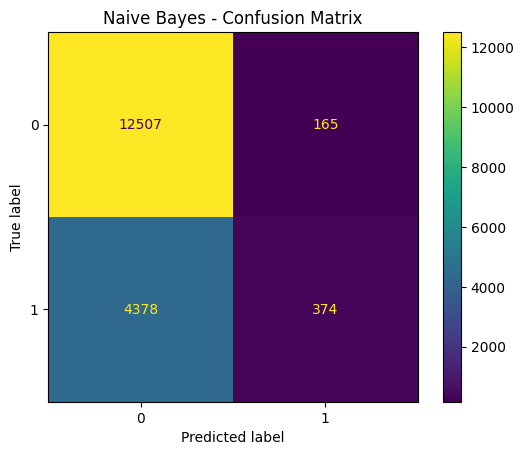

In [3]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'AUC': roc_auc_score(y_test, y_prob),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'MCC': matthews_corrcoef(y_test, y_pred),
}
metrics = {k: round(float(v), 4) for k, v in metrics.items()}
print(pd.Series(metrics))
print()
print(classification_report(y_test, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Naive Bayes - Confusion Matrix')
plt.show()

In [4]:
joblib.dump(model, os.path.join(ART, 'naive_bayes.joblib'))
with open(os.path.join(ART, 'metrics_naive_bayes.json'), 'w') as f:
    json.dump({'model': 'Naive Bayes', **metrics}, f, indent=2)
print('Saved model and metrics.')

Saved model and metrics.
